# Assignment 7 — Auto Insights
Executed in Python in this workspace. Upload this notebook and data.csv into the same Google Colab session and run the analysis cell to reproduce. Results files are written to results/. Training may take a few minutes.

The research goal is to explain relationships among vehicle characteristics and predict manufacturer suggested retail price (MSRP). The existing project’s original Cooper Union Car Dataset contains 11,914 rows. Removing 715 exact duplicate rows and excluding missing or nonpositive target prices leaves 11,199 records. No price outliers are removed. Findings 1–4 use all eligible records descriptively; their p-values are exploratory. Trims within model families are related, so conventional row-level p-values likely overstate precision. Effect sizes and plots receive more emphasis than significance.

The predictors are Year, Engine HP, Engine Cylinders, Make, Vehicle Size, Vehicle Style, Transmission Type, and Driven_Wheels. The target is MSRP. A fixed seed of 42 creates a group holdout: 8,875 training rows across 742 make/model families and 2,324 test rows across 186 different families. The split reserves roughly 20% of families, not necessarily 20% of rows. Three-fold GroupKFold on training data selects the winner by mean MAE. Median numeric imputation, missing-value indicators, standardization, most-frequent categorical imputation, and one-hot encoding are fitted inside each fold. All 16 regressors train on log(1 + MSRP), then predictions are converted back to dollars. The median baseline is additional and does not count among the 16 models. No hyperparameters are tuned using test results. Model settings appear in analysis.py and the notebook.

Linear Regression {"model": "Linear Regression", "cv_mae": 16064.728504804758, "cv_sd": 511.2446277917033, "test_mae": 10978.455739120089, "test_rmse": 20515.669186556384, "test_r2": 0.8180835465173005, "train_mae": 11918.00496025566, "seconds": 0.16104459762573242}
Ridge {"model": "Ridge", "cv_mae": 14575.079173364697, "cv_sd": 854.3482065202523, "test_mae": 12089.405692914985, "test_rmse": 25692.24396178688, "test_r2": 0.7146980892971375, "train_mae": 12168.278857197178, "seconds": 0.12201786041259766}
Lasso {"model": "Lasso", "cv_mae": 14992.308111934535, "cv_sd": 1109.2698811721073, "test_mae": 12642.103907688946, "test_rmse": 27996.58190068166, "test_r2": 0.6612255655203334, "train_mae": 12464.439058319458, "seconds": 0.14222073554992676}
Elastic Net {"model": "Elastic Net", "cv_mae": 14964.406465568094, "cv_sd": 841.0053770632586, "test_mae": 12278.641695849949, "test_rmse": 26466.715074020824, "test_r2": 0.6972384710235078, "train_mae": 12314.010291003091, "seconds": 0.162104368

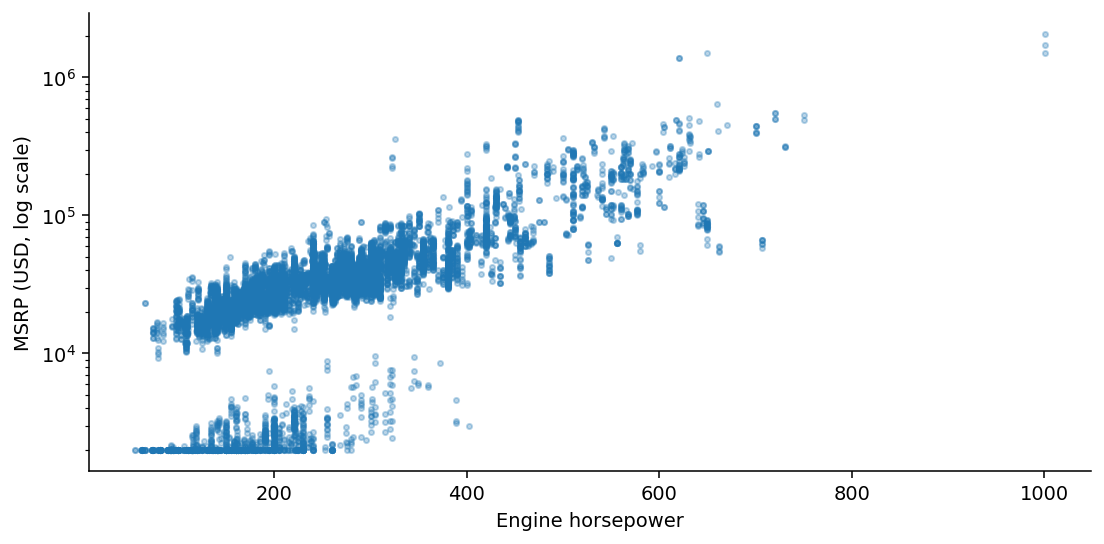

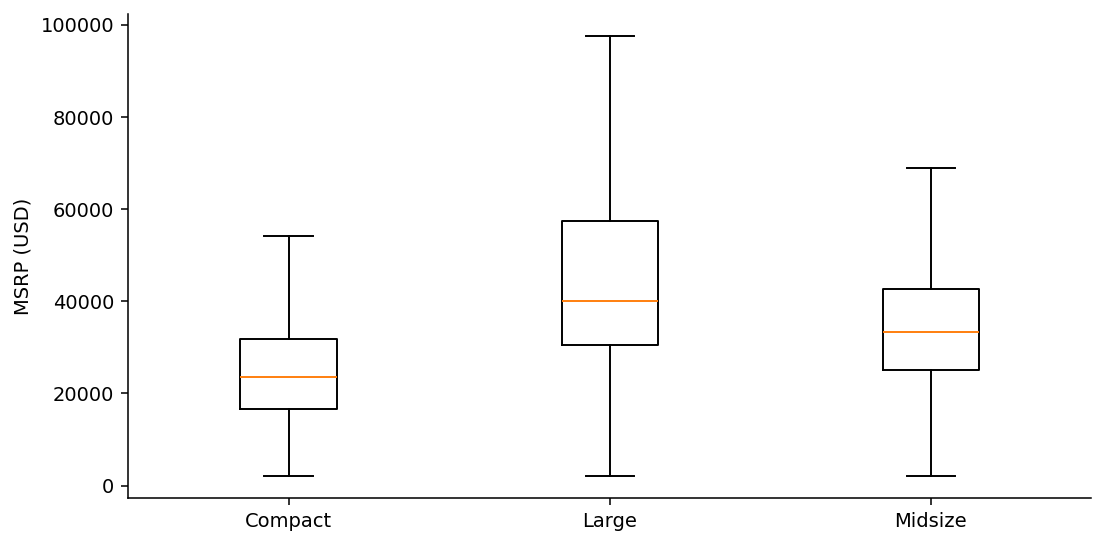

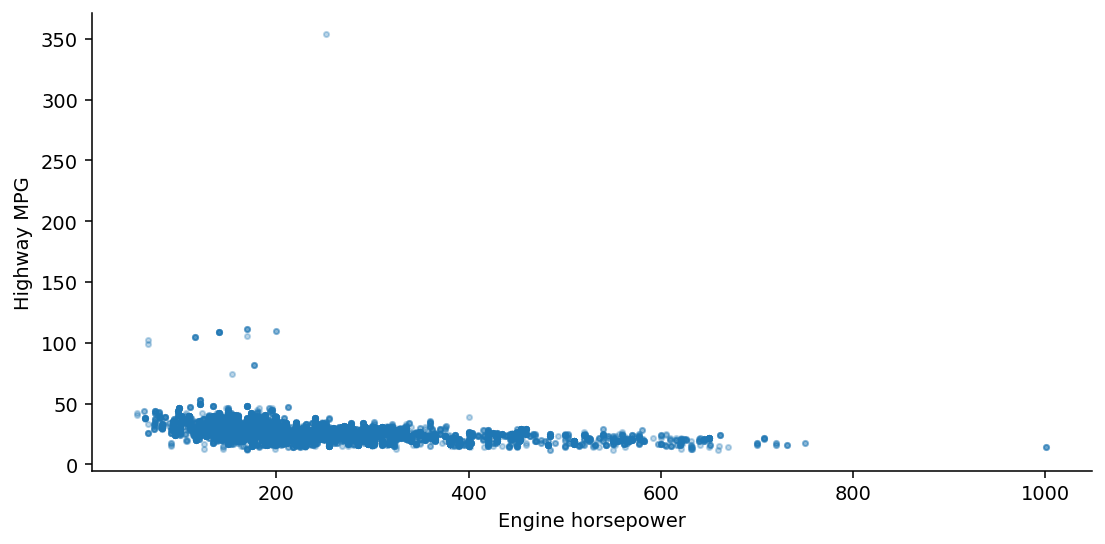

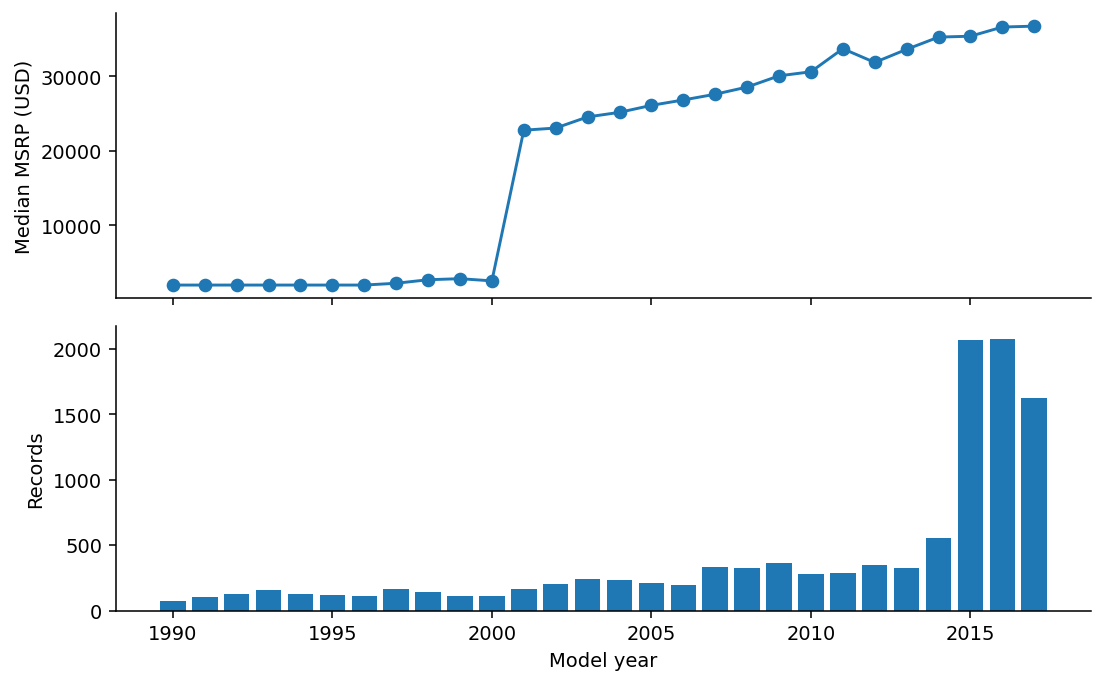

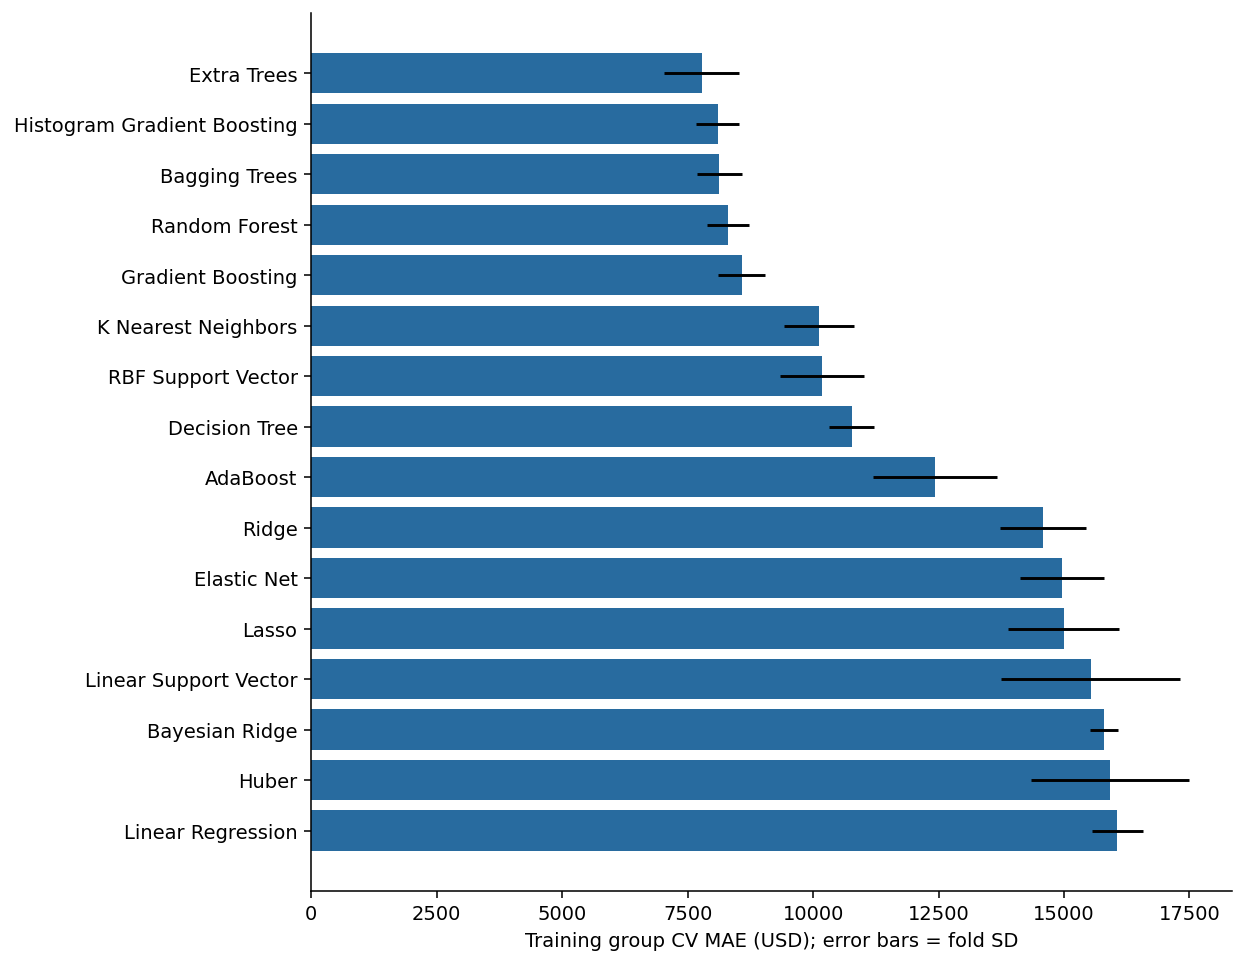

In [1]:
from pathlib import Path
import json, hashlib, time, warnings
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kruskal
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge, HuberRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, AdaBoostRegressor, BaggingRegressor
from sklearn.svm import SVR, LinearSVR
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT=Path.cwd(); OUT=ROOT/'results'; OUT.mkdir(exist_ok=True)
raw=pd.read_csv(ROOT/'data.csv')
d=raw.drop_duplicates().copy()
d=d.loc[d.MSRP.notna() & (d.MSRP>0)].reset_index(drop=True)
num=['Year','Engine HP','Engine Cylinders']
cat=['Make','Vehicle Size','Vehicle Style','Transmission Type','Driven_Wheels']
X=d[num+cat]; y=d.MSRP; groups=d.Make+'::'+d.Model
tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=42).split(X,y,groups))
assert not set(groups.iloc[tr]) & set(groups.iloc[te])
def prep():
    return ColumnTransformer([('num',make_pipeline(SimpleImputer(strategy='median',add_indicator=True),StandardScaler()),num),('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore',sparse_output=False)),cat)])
models={
 'Linear Regression':LinearRegression(), 'Ridge':Ridge(alpha=10),
 'Lasso':Lasso(alpha=.001,max_iter=5000), 'Elastic Net':ElasticNet(alpha=.001,l1_ratio=.5,max_iter=5000),
 'Bayesian Ridge':BayesianRidge(), 'Huber':HuberRegressor(max_iter=1000),
 'K Nearest Neighbors':KNeighborsRegressor(n_neighbors=7),
 'Decision Tree':DecisionTreeRegressor(max_depth=12,min_samples_leaf=5,random_state=42),
 'Random Forest':RandomForestRegressor(n_estimators=100,min_samples_leaf=2,random_state=42,n_jobs=2),
 'Extra Trees':ExtraTreesRegressor(n_estimators=100,min_samples_leaf=2,random_state=42,n_jobs=2),
 'Gradient Boosting':GradientBoostingRegressor(n_estimators=150,max_depth=3,random_state=42),
 'Histogram Gradient Boosting':HistGradientBoostingRegressor(max_iter=150,l2_regularization=1,random_state=42),
 'AdaBoost':AdaBoostRegressor(n_estimators=100,learning_rate=.05,random_state=42),
 'RBF Support Vector':SVR(C=10,epsilon=.05),
 'Linear Support Vector':LinearSVR(C=1,epsilon=.05,max_iter=10000,random_state=42),
 'Bagging Trees':BaggingRegressor(n_estimators=50,random_state=42,n_jobs=2)}
cv=list(GroupKFold(n_splits=3).split(X.iloc[tr],y.iloc[tr],groups.iloc[tr]))
rows=[]; fitted={}; predictions=pd.DataFrame({'actual':y.iloc[te]})
for name,model in models.items():
    start=time.time()
    pipe=TransformedTargetRegressor(regressor=make_pipeline(prep(),model),func=np.log1p,inverse_func=np.expm1)
    scores=-cross_val_score(pipe,X.iloc[tr],y.iloc[tr],cv=cv,scoring='neg_mean_absolute_error',n_jobs=1)
    pipe.fit(X.iloc[tr],y.iloc[tr]); pred=pipe.predict(X.iloc[te])
    rows.append(dict(model=name,cv_mae=scores.mean(),cv_sd=scores.std(),test_mae=mean_absolute_error(y.iloc[te],pred),test_rmse=np.sqrt(mean_squared_error(y.iloc[te],pred)),test_r2=r2_score(y.iloc[te],pred),train_mae=mean_absolute_error(y.iloc[tr],pipe.predict(X.iloc[tr])),seconds=time.time()-start))
    fitted[name]=pipe; predictions[name]=pred
    print(name, json.dumps(rows[-1]),flush=True)
metrics=pd.DataFrame(rows).sort_values('cv_mae'); metrics.to_csv(OUT/'model_metrics.csv',index=False)
predictions.to_csv(OUT/'test_predictions.csv',index=True)
winner=metrics.iloc[0]; best=winner['model']
baseline=DummyRegressor(strategy='median').fit(X.iloc[tr],y.iloc[tr]); bp=baseline.predict(X.iloc[te])
bmae=mean_absolute_error(y.iloc[te],bp)
split=d[['Make','Model','Year']].copy();split['split']='train';split.loc[te,'split']='test';split.to_csv(OUT/'split.csv',index=False)
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
def save(name):
    plt.tight_layout();plt.savefig(OUT/name,dpi=140,bbox_inches='tight');plt.close()
valid=d[['Engine HP','MSRP']].dropna(); rho,p=spearmanr(valid['Engine HP'],valid.MSRP)
plt.figure(figsize=(8,4));plt.scatter(valid['Engine HP'],valid.MSRP,s=7,alpha=.3);plt.yscale('log');plt.xlabel('Engine horsepower');plt.ylabel('MSRP (USD, log scale)');save('horsepower.png')
sizes=d.groupby('Vehicle Size').MSRP.agg(['count','median','mean']);sizes.to_csv(OUT/'size_summary.csv')
h,kp=kruskal(*(g.MSRP for _,g in d.groupby('Vehicle Size')))
plt.figure(figsize=(8,4));plt.boxplot([g.MSRP for _,g in d.groupby('Vehicle Size')],tick_labels=list(sizes.index),showfliers=False);plt.ylabel('MSRP (USD)');save('size.png')
mpg=d[['Engine HP','highway MPG']].dropna(); mr,mp=spearmanr(mpg['Engine HP'],mpg['highway MPG'])
plt.figure(figsize=(8,4));plt.scatter(mpg['Engine HP'],mpg['highway MPG'],s=7,alpha=.3);plt.xlabel('Engine horsepower');plt.ylabel('Highway MPG');save('mpg.png')
years=d.groupby('Year').MSRP.agg(['count','median']);years.to_csv(OUT/'year_summary.csv')
fig,axes=plt.subplots(2,1,figsize=(8,5),sharex=True);axes[0].plot(years.index,years['median'],marker='o');axes[0].set_ylabel('Median MSRP (USD)');axes[1].bar(years.index,years['count']);axes[1].set_ylabel('Records');axes[1].set_xlabel('Model year');save('years.png')
fig,ax=plt.subplots(figsize=(9,7));ax.barh(metrics.model,metrics.cv_mae,xerr=metrics.cv_sd,color='#286b9f');ax.invert_yaxis();ax.set_xlabel('Training group CV MAE (USD); error bars = fold SD');save('models.png')
fig,ax=plt.subplots(figsize=(8,4));ax.scatter(y.iloc[te],predictions[best],s=8,alpha=.35);lo=1;hi=max(y.iloc[te].max(),predictions[best].max());ax.plot([lo,hi],[lo,hi],'k--');ax.set(xscale='log',yscale='log',xlabel='Actual MSRP (USD, log scale)',ylabel='Predicted MSRP (USD, log scale)',title=best);save('predictions.png')
summary=dict(raw_n=len(raw),analysis_n=len(d),duplicates_removed=len(raw)-len(raw.drop_duplicates()),train_n=len(tr),test_n=len(te),train_groups=groups.iloc[tr].nunique(),test_groups=groups.iloc[te].nunique(),hp_rho=rho,hp_p=p,hp_n=len(valid),size_h=h,size_p=kp,mpg_rho=mr,mpg_p=mp,mpg_n=len(mpg),best=best,baseline_mae=bmae,sklearn=sklearn.__version__,sha256=hashlib.sha256((ROOT/'data.csv').read_bytes()).hexdigest())
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print('SUMMARY',json.dumps(summary),flush=True)


## 1. Horsepower and MSRP

Research Question: Is engine horsepower associated with MSRP?

Evidence: Spearman rho = 0.833, p < 0.001, n = 11,130 complete records.

Visualization: horsepower.png (shown in the executed output above).

Analysis: The rank correlation measures a monotonic relationship and is less sensitive to extreme prices than a raw-price Pearson correlation. The scatterplot uses a log price axis so lower-priced vehicles remain visible.

Interpretation: Higher horsepower is associated with higher listed MSRP in this sample. This supports horsepower as a price predictor. Brand, luxury equipment, and vehicle type could explain part of the relationship. Horsepower alone does not establish a causal price effect.

## 2. Price differences by vehicle size

Research Question: Does MSRP differ among compact, midsize, and large vehicles?

Evidence: Compact: median $23,650, n=4,395; Large: median $39,970, n=2,683; Midsize: median $33,295, n=4,121. Kruskal–Wallis H = 1519.16, p < 0.001.

Visualization: size.png (shown in the executed output above).

Analysis: The boxplot shows medians and spread; individual outlier points are hidden for readability but remain in all calculations. Kruskal–Wallis tests whether group distributions differ. It does not prove every pair differs or isolate a size effect.

Interpretation: Vehicle size is associated with price differences and is a useful candidate predictor. Differences in brand and equipment mix prevent attributing the full price gap to size. Pairwise claims would require post-hoc tests.

## 3. Horsepower and fuel economy

Research Question: Is higher horsepower associated with lower highway fuel economy?

Evidence: Spearman rho = -0.510, p < 0.001, n = 11,130 complete records.

Visualization: mpg.png (shown in the executed output above).

Analysis: The scatterplot shows the direction and spread of the association. Some unusually high mileage values could reflect alternative-powertrain vehicles or different efficiency reporting and should be checked before drawing powertrain-specific conclusions.

Interpretation: Higher horsepower is associated with lower highway MPG overall in this sample. This suggests a performance–efficiency tradeoff, but it does not prove increasing horsepower causes a specific MPG loss. Fuel economy is examined descriptively and is excluded from the eight-feature MSRP benchmark.

## 4. MSRP across model years

Research Question: How does the distribution of MSRP vary by model year?

Evidence: Model years span 1990–2017. Median MSRP is $2,000 in 1990 and $36,720 in 2017. Annual sample counts are shown below the median line.

Visualization: years.png (shown in the executed output above).

Analysis: This is a cross-sectional comparison by model year, not a longitudinal study. The available makes, models, equipment, and number of observations vary across years. Prices are not adjusted for inflation. Older observations with low or repeated prices require source validation.

Interpretation: The sample shows a model-year pattern in listed MSRP. It does not measure annual market inflation, depreciation of one car, or a forecast. Year is included as a predictive feature, while the interpretation remains limited to this dataset.

## 5. Comparing 16 machine learning models

Research Question: Which tested model predicts MSRP best for held-out make/model families?

Evidence: Extra Trees has the lowest training cross-validation MAE ($7,780; fold SD $747). On the held-out test set: MAE $5,575, RMSE $13,431, R² 0.922. Median-baseline test MAE is $19,728. The selected model reduces test MAE by 71.7% relative to that baseline.

Visualization: models.png (shown in the executed output above).

Analysis: Models are ranked by mean training cross-validation MAE, not by test results. The same group folds, features, and test set are used for all models. Fold standard deviation describes variability across three folds; it is not a confidence interval. MAE reflects typical absolute dollar error; RMSE emphasizes large errors; R² compares squared error with a test-mean reference.

Interpretation: The selected model is the strongest candidate under this experiment’s MAE criterion. Extra Trees averages randomized decision trees, which can capture nonlinear price relationships and interactions among brand, horsepower, and vehicle type. Averaging may reduce variance relative to a single tree, although this experiment does not isolate that mechanism. Random Forest has a lower test RMSE and higher test R², so Extra Trees does not lead on every metric. Compare its training error, fold variability, and RMSE before deployment. This is a benchmark with fixed settings, not exhaustive tuning or proof of universal superiority.

## Results table

<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>model</th>
      <th>cv_mae</th>
      <th>cv_sd</th>
      <th>test_mae</th>
      <th>test_rmse</th>
      <th>test_r2</th>
      <th>train_mae</th>
      <th>seconds</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Extra Trees</td>
      <td>7779.853</td>
      <td>746.550</td>
      <td>5575.141</td>
      <td>13431.450</td>
      <td>0.922</td>
      <td>2269.479</td>
      <td>4.363</td>
    </tr>
    <tr>
      <td>Histogram Gradient Boosting</td>
      <td>8099.232</td>
      <td>430.296</td>
      <td>5912.286</td>
      <td>14665.978</td>
      <td>0.907</td>
      <td>4012.223</td>
      <td>2.491</td>
    </tr>
    <tr>
      <td>Bagging Trees</td>
      <td>8134.556</td>
      <td>452.278</td>
      <td>5864.204</td>
      <td>12870.371</td>
      <td>0.928</td>
      <td>2284.230</td>
      <td>4.561</td>
    </tr>
    <tr>
      <td>Random Forest</td>
      <td>8306.027</td>
      <td>424.298</td>
      <td>5806.736</td>
      <td>12497.757</td>
      <td>0.932</td>
      <td>2708.728</td>
      <td>4.122</td>
    </tr>
    <tr>
      <td>Gradient Boosting</td>
      <td>8578.488</td>
      <td>469.384</td>
      <td>7232.525</td>
      <td>17493.094</td>
      <td>0.868</td>
      <td>5876.194</td>
      <td>4.271</td>
    </tr>
    <tr>
      <td>K Nearest Neighbors</td>
      <td>10124.906</td>
      <td>694.712</td>
      <td>8282.687</td>
      <td>17652.196</td>
      <td>0.865</td>
      <td>4585.517</td>
      <td>0.628</td>
    </tr>
    <tr>
      <td>RBF Support Vector</td>
      <td>10179.490</td>
      <td>835.900</td>
      <td>7485.640</td>
      <td>15707.855</td>
      <td>0.893</td>
      <td>3088.525</td>
      <td>13.385</td>
    </tr>
    <tr>
      <td>Decision Tree</td>
      <td>10773.265</td>
      <td>447.096</td>
      <td>7874.289</td>
      <td>21201.051</td>
      <td>0.806</td>
      <td>4782.998</td>
      <td>0.171</td>
    </tr>
    <tr>
      <td>AdaBoost</td>
      <td>12432.111</td>
      <td>1231.297</td>
      <td>10631.920</td>
      <td>23076.854</td>
      <td>0.770</td>
      <td>11644.227</td>
      <td>3.651</td>
    </tr>
    <tr>
      <td>Ridge</td>
      <td>14575.079</td>
      <td>854.348</td>
      <td>12089.406</td>
      <td>25692.244</td>
      <td>0.715</td>
      <td>12168.279</td>
      <td>0.122</td>
    </tr>
    <tr>
      <td>Elastic Net</td>
      <td>14964.406</td>
      <td>841.005</td>
      <td>12278.642</td>
      <td>26466.715</td>
      <td>0.697</td>
      <td>12314.010</td>
      <td>0.162</td>
    </tr>
    <tr>
      <td>Lasso</td>
      <td>14992.308</td>
      <td>1109.270</td>
      <td>12642.104</td>
      <td>27996.582</td>
      <td>0.661</td>
      <td>12464.439</td>
      <td>0.142</td>
    </tr>
    <tr>
      <td>Linear Support Vector</td>
      <td>15530.492</td>
      <td>1779.828</td>
      <td>10052.136</td>
      <td>20633.040</td>
      <td>0.816</td>
      <td>9973.511</td>
      <td>2.169</td>
    </tr>
    <tr>
      <td>Bayesian Ridge</td>
      <td>15795.341</td>
      <td>274.190</td>
      <td>11055.175</td>
      <td>20733.338</td>
      <td>0.814</td>
      <td>11981.603</td>
      <td>0.236</td>
    </tr>
    <tr>
      <td>Huber</td>
      <td>15915.648</td>
      <td>1567.433</td>
      <td>10162.316</td>
      <td>20258.292</td>
      <td>0.823</td>
      <td>10498.608</td>
      <td>1.016</td>
    </tr>
    <tr>
      <td>Linear Regression</td>
      <td>16064.729</td>
      <td>511.245</td>
      <td>10978.456</td>
      <td>20515.669</td>
      <td>0.818</td>
      <td>11918.005</td>
      <td>0.161</td>
    </tr>
  </tbody>
</table>

## Limitations
Limitations: This convenience dataset is not a random sample of today’s vehicle market. MSRP is not a transaction price. Related trims, uneven brand coverage, extreme prices, model-year composition, and possible legacy price conventions limit generalization. Group holdout reduces model-family leakage but does not test unseen manufacturers or future years. Log-target fitting prioritizes relative fit and can underpredict high prices; dollar MAE and RMSE expose that limitation. Results depend on a single held-out split and fixed model settings. No causal claims or production-readiness claims are supported.

## Results-section foundation
Together, these findings support using engine characteristics, vehicle categories, and model year to study price differences. Horsepower and size show descriptive associations with MSRP, and the horsepower–MPG relationship adds an efficiency dimension. Model-year results require caution because the sample composition changes. Among the 16 tested algorithms, Extra Trees has the best training group cross-validation MAE and achieves a held-out MAE of $5,575. These results provide a foundation for the research paper’s Results section, followed by a Discussion of confounding, sample coverage, and generalization.

Source: https://www.kaggle.com/datasets/CooperUnion/cardataset